# RQ3: planning interventions on the Bugis network

Five visuals for the group, each answering one question:

1. **What did we change?** The three interventions on the map.
2. **Did anything move the critical point?** The speed curves, zoomed in where they cross the half-speed line.
3. **How sure are we?** Each seed's shift in critical density.
4. **Where does the closure push traffic?** The congestion-change map around Victoria St, with a density slider.
5. **Does the new link make its neighbours worse?** The local Braess effect: the congestion-change map around the Java Road link, with a density slider.

**Two ways to run it:**

- **Option A, Colab:** run the cells from top to bottom. The first code cell asks you to upload the 9 files below if they are not there yet.
- **Option B, your own computer:** work straight from your local copy of the repository, with nothing to upload. See the next cell.

The 9 files:

| Files | Where they are in the repository |
|---|---|
| `bugis_all_base.net.xml`, `bugis_all_closure.net.xml`, `bugis_all_lanecut.net.xml`, `bugis_all_newlink.net.xml` | `scenarios/city/` (main) |
| `bugis_all_base_controller.csv`, `bugis_all_closure_controller.csv`, `bugis_all_newlink_controller.csv`, `bugis_all_lanecut_controller.csv` | `results/city/` (branch `c/planning-results`) |
| `planning_edges.csv` | `results/city/planning_seeds1to10/` (branch `c/planning-results`) |

No SUMO is needed: the road shapes are read straight from the `.net.xml` files.

## Option B: run from your local repository

Colab runs on Google's machines and cannot see the folders on your computer, so Option B runs the notebook locally, in **VS Code** (with the Python and Jupyter extensions) or in **Jupyter** (`pip install notebook`, then `jupyter notebook`).

**1. Bring your local copy up to date.** In Git Bash, inside the repository folder:

```
git status
git fetch origin
git switch main
git pull
```

`git status` comes first, to make sure no uncommitted changes get in the way.

**2. Check where C's results are:**

```
ls results/city/ runs/cdata/
```

- If you see `bugis_all_base_controller.csv` (here or in `runs/cdata/`), main has everything. Go to step 3.
- If not, switch to C's branch, which has the networks and the results together:

  ```
  git switch c/planning-results
  git pull
  ```

  Do not commit anything on that branch. Switch back with `git switch main` when you are done.

**3. Tell the notebook where the repository is.** In the next code cell, set `REPO_DIR` to your repository folder, for example:

```python
REPO_DIR = r"C:\Users\you\Documents\agent-based-traffic-modeling"
```

The cell then searches the repository for the 9 files and prints where it found each one, so it works wherever they are kept (for example C's tables in `runs/cdata/`). No upload dialog appears. Leave `REPO_DIR = None` for Option A (Colab).

**If a file is reported missing,** it is not in your copy under that name: check the branch (step 2), or look for it with `find . -name "bugis_all_*"` in Git Bash.

In [1]:
# --- Setup: libraries, where the files are, and (in Colab) the upload dialog ---------------------
import math, os
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle

REPO_DIR = None                      # Option B: your local repository folder, e.g. r"C:\Users\you\agent-based-traffic-modeling"
VARIANTS = ["base", "closure", "newlink", "lanecut"]
if REPO_DIR:                         # Option B: find each file wherever it is in the repository
    import glob
    DATA_DIR = REPO_DIR
    def find(name, prefer=()):
        """Path of `name` inside REPO_DIR (relative to it); with several copies, the first whose
        folder contains one of `prefer`, e.g. 'runs/cdata'."""
        hits = sorted(h for h in glob.glob(os.path.join(REPO_DIR, "**", name), recursive=True)
                      if ".git" not in h.split(os.sep))
        rel = [os.path.relpath(h, REPO_DIR).replace(os.sep, "/") for h in hits]
        for p in prefer:
            for r in rel:
                if p in r:
                    return r
        return rel[0] if rel else name
    CSV_FOLDERS = ("runs/cdata", "results/city")      # where C's result tables may be
    NET_FILES = {v: find(f"bugis_all_{v}.net.xml", ("scenarios/city",)) for v in VARIANTS}
    RESULT_FILES = {v: find(f"bugis_all_{v}_controller.csv", CSV_FOLDERS) for v in VARIANTS}
    EDGE_FILE = find("planning_edges.csv", ("seeds1to10",) + CSV_FOLDERS)
    for f in list(NET_FILES.values()) + list(RESULT_FILES.values()) + [EDGE_FILE]:
        print("using", f)
else:                                # Option A (Colab): all 9 files in the current folder
    DATA_DIR = "."
    NET_FILES = {v: f"bugis_all_{v}.net.xml" for v in VARIANTS}
    RESULT_FILES = {v: f"bugis_all_{v}_controller.csv" for v in VARIANTS}
    EDGE_FILE = "planning_edges.csv"
NEEDED = list(NET_FILES.values()) + list(RESULT_FILES.values()) + [EDGE_FILE]

missing = [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    try:                             # in Colab: open the upload dialog for the missing files
        from google.colab import files
        print("Please upload:", ", ".join(missing))
        files.upload()
    except ImportError:              # not in Colab: just say what is missing
        print("Missing files (put them in DATA_DIR):", ", ".join(missing))
missing = [f for f in NEEDED if not os.path.exists(os.path.join(DATA_DIR, f))]
print("All 9 files found." if not missing else f"Still missing: {missing}")

Please upload: bugis_all_base.net.xml, bugis_all_closure.net.xml, bugis_all_newlink.net.xml, bugis_all_lanecut.net.xml, bugis_all_base_controller.csv, bugis_all_closure_controller.csv, bugis_all_newlink_controller.csv, bugis_all_lanecut_controller.csv, planning_edges.csv


Saving planning_edges.csv to planning_edges.csv
Saving bugis_all_lanecut_controller.csv to bugis_all_lanecut_controller.csv
Saving bugis_all_newlink_controller.csv to bugis_all_newlink_controller.csv
Saving bugis_all_closure_controller.csv to bugis_all_closure_controller.csv
Saving bugis_all_base_controller.csv to bugis_all_base_controller.csv
Saving bugis_all_newlink.net.xml to bugis_all_newlink.net.xml
Saving bugis_all_lanecut.net.xml to bugis_all_lanecut.net.xml
Saving bugis_all_closure.net.xml to bugis_all_closure.net.xml
Saving bugis_all_base.net.xml to bugis_all_base.net.xml
All 9 files found.


In [2]:
# --- Shared helpers: names, colours, reading the networks and the results --------------
LABELS = {"base": "Baseline", "closure": "Victoria St closed",
          "newlink": "Java Road connection", "lanecut": "Victoria St lane cut"}
COLORS = {"base": "#52514e", "closure": "#2a78d6", "newlink": "#eb6834", "lanecut": "#1baf7a"}
MARKERS = {"base": "o", "closure": "s", "newlink": "^", "lanecut": "D"}

def read_net(path):
    """{edge id: (shape as an (n, 2) array in metres, number of lanes)} for the normal roads."""
    roads = {}
    for _, el in ET.iterparse(path):
        if el.tag == "edge" and el.get("function") != "internal":
            lanes = el.findall("lane")
            if lanes:
                shape = lanes[len(lanes) // 2].get("shape")          # the middle lane's line
                xy = np.array([[float(c) for c in p.split(",")[:2]] for p in shape.split()])
                roads[el.get("id")] = (xy, len(lanes))
            el.clear()
        elif el.tag in ("junction", "connection", "tlLogic"):
            el.clear()                                             # keeps memory low
    return roads

def load_runs():
    """All valid runs of the four sweeps, one row per run: variant, seed, density k, speed v, flow q."""
    frames = []
    for v, f in RESULT_FILES.items():
        d = pd.read_csv(os.path.join(DATA_DIR, f))
        d = d[d["valid"].astype(str) == "True"].copy()           # a run with a collision is left out
        d["variant"] = v
        frames.append(d)
    d = pd.concat(frames)
    return pd.DataFrame({"variant": d["variant"], "seed": d["seed"], "k": d["city_k_target"],
                         "v": d["mean_speed_mps"], "q": d["flow_veh_h"]})

def half_speed_density(k, v, v_star):
    """Density where speed first drops below v_star, straight line between the two points around it."""
    k, v = np.asarray(k, float), np.asarray(v, float)
    below = np.flatnonzero(v < v_star)
    if len(below) == 0 or below[0] == 0:
        return math.nan
    i = below[0]
    return k[i - 1] + (v_star - v[i - 1]) * (k[i] - k[i - 1]) / (v[i] - v[i - 1])

nets = {v: read_net(os.path.join(DATA_DIR, f)) for v, f in NET_FILES.items()}
runs = load_runs()
print({v: len(n) for v, n in nets.items()}, "roads per network;", len(runs), "valid runs")

{'base': 1129, 'closure': 1127, 'newlink': 1131, 'lanecut': 1129} roads per network; 126 valid runs


## 1. What did we change?

All four networks are the same Bugis road network, except for one change each:

- **Victoria St closed:** one short stretch of Victoria Street removed in both directions (the busiest stretch whose removal still lets every road be reached from every other).
- **Victoria St lane cut:** the same stretch with one lane less each way (4 + 3 lanes become 3 + 2).
- **Java Road connection:** a new 148 m two-way link (the one that cuts travel times the most).

The cell finds the changes by comparing each network with the baseline, so the map is drawn from the files themselves.

closed: ['538223044#0', '630437927#0'] | lane cut: ['538223044#0', '630437927#0'] | new: ['newlink_2015359629_cluster_240661028_240661099', 'newlink_cluster_240661028_240661099_2015359629']


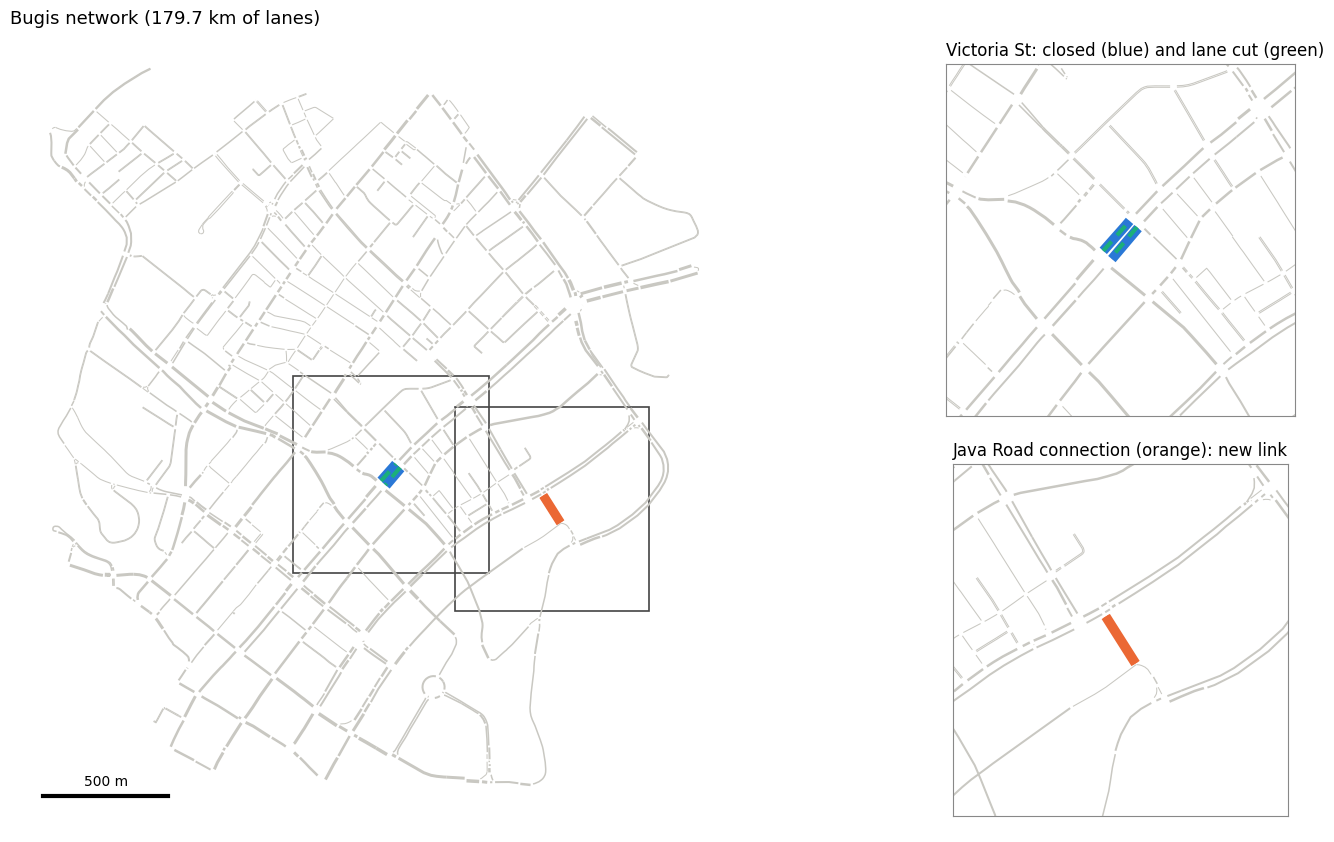

In [3]:
# --- Visual 1: the three interventions on the map -------------------------------------
base = nets["base"]
closed = [e for e in base if e not in nets["closure"]]                         # roads that disappear
lane_cut = [e for e in base if e in nets["lanecut"] and nets["lanecut"][e][1] < base[e][1]]  # fewer lanes
new = [e for e in nets["newlink"] if e not in base]                            # roads that appear
print("closed:", closed, "| lane cut:", lane_cut, "| new:", new)

def draw_roads(ax, roads, color="#c9c8c2"):
    """All roads in light grey, wider for more lanes."""
    ax.add_collection(LineCollection([s for s, _ in roads.values()], colors=color,
                                     linewidths=[0.4 + 0.35 * n for _, n in roads.values()]))

def box_around(edge_ids, roads, margin):
    """(xmin, xmax, ymin, ymax) around some roads, plus a margin in metres."""
    xy = np.vstack([roads[e][0] for e in edge_ids])
    return xy[:, 0].min() - margin, xy[:, 0].max() + margin, xy[:, 1].min() - margin, xy[:, 1].max() + margin

fig = plt.figure(figsize=(15, 8))
ax_all = fig.add_axes([0.0, 0.0, 0.52, 1.0])
ax_vic = fig.add_axes([0.55, 0.52, 0.42, 0.44])
ax_java = fig.add_axes([0.55, 0.02, 0.42, 0.44])
zooms = [(ax_vic, box_around(closed, base, 350), "Victoria St: closed (blue) and lane cut (green)"),
         (ax_java, box_around(new, nets["newlink"], 350), "Java Road connection (orange): new link")]

for ax in (ax_all, ax_vic, ax_java):
    draw_roads(ax, base)
    ax.add_collection(LineCollection([base[e][0] for e in closed], colors=COLORS["closure"], linewidths=7))
    ax.add_collection(LineCollection([nets["lanecut"][e][0] for e in lane_cut], colors=COLORS["lanecut"],
                                     linewidths=3, linestyles=(0, (3, 2))))
    ax.add_collection(LineCollection([nets["newlink"][e][0] for e in new], colors=COLORS["newlink"], linewidths=6))
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

ax_all.autoscale_view()
ax_all.set_title("Bugis network (179.7 km of lanes)", loc="left", fontsize=13)
for ax, (x0, x1, y0, y1), title in zooms:
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_title(title, loc="left", fontsize=12)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#888888")
    ax_all.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#444444", lw=1.2))  # where the zoom is
x0, x1 = ax_all.get_xlim(); y0, y1 = ax_all.get_ylim()
ax_all.plot([x0 + 100, x0 + 600], [y0 + 100, y0 + 100], color="black", lw=3)           # 500 m scale bar
ax_all.text(x0 + 350, y0 + 140, "500 m", ha="center", fontsize=10)
plt.show()

## 2. Did anything move the critical point?

For each network we plot the **mean speed** against **density** (cars per km of lane), averaged over the 3 seeds.
The **critical density** is where the speed falls to **half the baseline's speed when the network is nearly empty** (2.5 veh/km): about 3.39 m/s, the same line for all four networks.

On the full range (left) the four curves sit on top of each other. Zoomed in where they cross the half-speed line (right), the closure crosses **earlier**: congestion starts with fewer cars.

near-empty speed 6.77 m/s, half-speed line 3.39 m/s
{'Baseline': np.float64(13.35), 'Victoria St closed': np.float64(12.9), 'Java Road connection': np.float64(13.36), 'Victoria St lane cut': np.float64(13.21)}


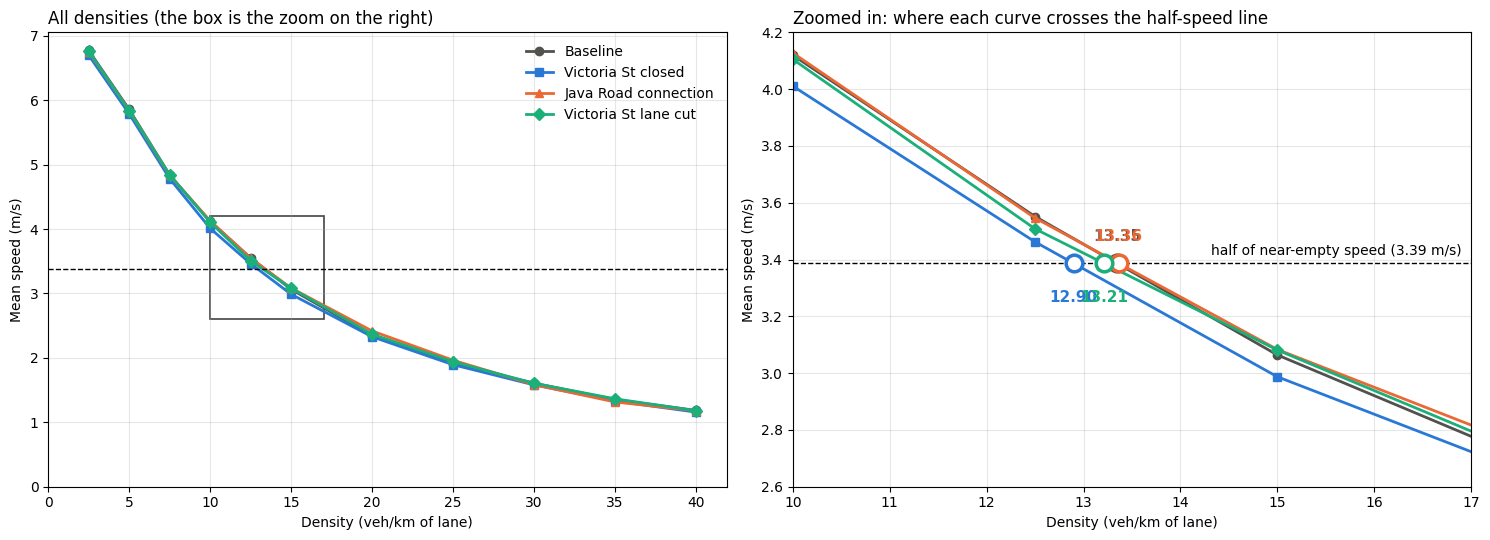

In [4]:
# --- Visual 2: speed curves and where each crosses the half-speed line ------------------
curves = runs.groupby(["variant", "k"]).v.mean().unstack(0)           # seed-mean speed, one column per variant
v0 = curves.loc[curves.index.min(), "base"]                           # baseline's near-empty speed (2.5 veh/km)
v_star = v0 / 2                                                       # the half-speed line
k_half = {v: half_speed_density(curves.index, curves[v], v_star) for v in VARIANTS}
print(f"near-empty speed {v0:.2f} m/s, half-speed line {v_star:.2f} m/s")
print({LABELS[v]: round(k, 2) for v, k in k_half.items()})

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(15, 5.5))
for v in VARIANTS:
    kw = dict(color=COLORS[v], marker=MARKERS[v], lw=2, ms=6, label=LABELS[v])
    ax_full.plot(curves.index, curves[v], **kw)
    ax_zoom.plot(curves.index, curves[v], **kw)
    ax_zoom.plot([k_half[v]], [v_star], marker="o", ms=12, mfc="white", mec=COLORS[v], mew=2.5, zorder=5)
    ax_zoom.annotate(f"{k_half[v]:.2f}", (k_half[v], v_star), xytext=(0, -28 if v in ("closure", "lanecut") else 16),
                     textcoords="offset points", ha="center", color=COLORS[v], fontsize=11, fontweight="bold")
for ax in (ax_full, ax_zoom):
    ax.axhline(v_star, color="black", ls="--", lw=1)
    ax.set_xlabel("Density (veh/km of lane)"); ax.set_ylabel("Mean speed (m/s)")
    ax.grid(alpha=0.3)
ax_full.set_ylim(bottom=0); ax_full.set_xlim(left=0)
ax_full.add_patch(Rectangle((10, 2.6), 7, 1.6, fill=False, ec="#444444", lw=1.2))   # the zoomed area
ax_full.set_title("All densities (the box is the zoom on the right)", loc="left")
ax_full.legend(frameon=False)
ax_zoom.set_xlim(10, 17); ax_zoom.set_ylim(2.6, 4.2)
ax_zoom.set_title("Zoomed in: where each curve crosses the half-speed line", loc="left")
ax_zoom.text(16.9, v_star + 0.03, f"half of near-empty speed ({v_star:.2f} m/s)", ha="right", fontsize=10)
plt.tight_layout(); plt.show()

## 3. How sure are we?

Each network was run with **3 seeds** (3 random versions of who starts where and goes where). For each seed we compare a variant with the baseline **on the same seed** and work out how far the critical density moved.

- **Dots:** each seed's shift. **Bar:** the overall shift (from the seed-averaged curves).
- If all three dots sit on the same side of zero, the seeds agree on the direction.

Only the closure's three dots are all below zero. The lane cut and the Java Road connection straddle zero: no clear effect. With only 3 seeds we show the seed values rather than a precise confidence interval (E's advice).

Victoria St closed     overall -0.45; seeds -0.79, -0.51, -0.27
Victoria St lane cut   overall -0.13; seeds -0.47, -0.16, +0.03
Java Road connection   overall +0.02; seeds -0.17, -0.22, +0.22


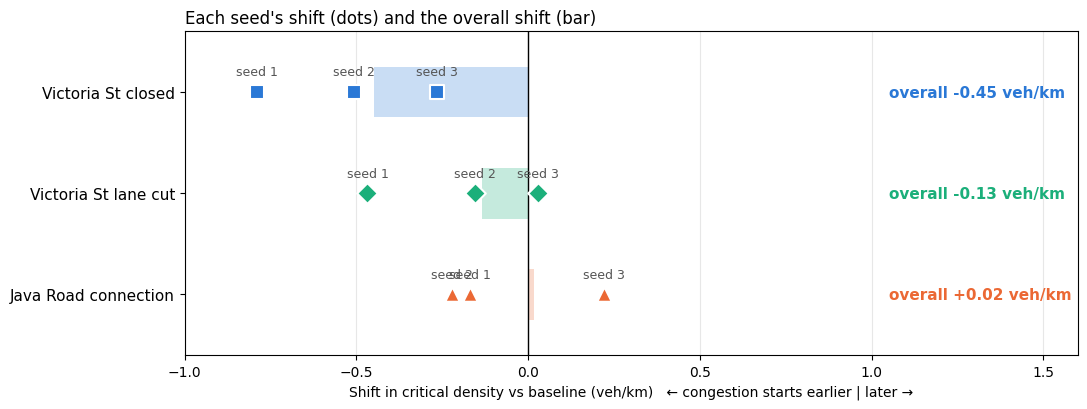

In [5]:
# --- Visual 3: each seed's shift in critical density ------------------------------------
def paired_shifts(variant):
    """Per seed: critical density of the variant minus the baseline's, on the runs both have
    (if a run is missing on one side, its partner is left out too)."""
    a, b = runs[runs.variant == variant], runs[runs.variant == "base"]
    both = set(zip(a.k, a.seed)) & set(zip(b.k, b.seed))
    keep = lambda d: d[[kv in both for kv in zip(d.k, d.seed)]]
    a, b = keep(a), keep(b)
    out = {}
    for s in sorted(a.seed.unique()):
        ka, kb = (half_speed_density(d[d.seed == s].sort_values("k").k, d[d.seed == s].sort_values("k").v, v_star)
                  for d in (a, b))
        out[int(s)] = ka - kb
    return out

others = ["closure", "lanecut", "newlink"]
fig, ax = plt.subplots(figsize=(11, 4.2))
for row, v in enumerate(others):
    y = len(others) - 1 - row
    shifts = paired_shifts(v)
    overall = k_half[v] - k_half["base"]
    ax.barh(y, overall, height=0.5, color=COLORS[v], alpha=0.25)
    ax.scatter(list(shifts.values()), [y] * len(shifts), s=110, color=COLORS[v], marker=MARKERS[v],
               zorder=3, edgecolor="white", linewidth=1.5)
    for s, d in shifts.items():
        ax.annotate(f"seed {s}", (d, y), xytext=(0, 12), textcoords="offset points", ha="center",
                    fontsize=9, color="#555555")
    ax.text(1.05, y, f"overall {overall:+.2f} veh/km", va="center", fontsize=11, color=COLORS[v],
            fontweight="bold")
    print(f"{LABELS[v]:<22} overall {overall:+.2f}; seeds " + ", ".join(f"{d:+.2f}" for d in shifts.values()))
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(others))); ax.set_yticklabels([LABELS[v] for v in reversed(others)], fontsize=11)
ax.set_xlim(-1.0, 1.6); ax.set_ylim(-0.6, len(others) - 0.4)
ax.set_xlabel("Shift in critical density vs baseline (veh/km)   ← congestion starts earlier | later →")
ax.set_title("Each seed's shift (dots) and the overall shift (bar)", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Where does the closure push traffic?

Each road is **congested** when its speed is below half its own near-empty speed. For every road we take the **share of time it was congested**, averaged over the seeds, and compare the closure with the baseline:

- **Red:** more congested with Victoria St closed. **Blue:** less congested. **Grey:** a change under 5 percentage points, or one the seeds don't agree on.
- **Dashed black:** the closed stretch.

At 12.5 veh/km (around the critical point) the streets right next to the closed block turn red: traffic squeezes onto them. Roads that used to feed Victoria St turn blue.
*Caution:* the closure has only 3 seeds, so scattered single roads elsewhere may be noise; trust the cluster around the closure.

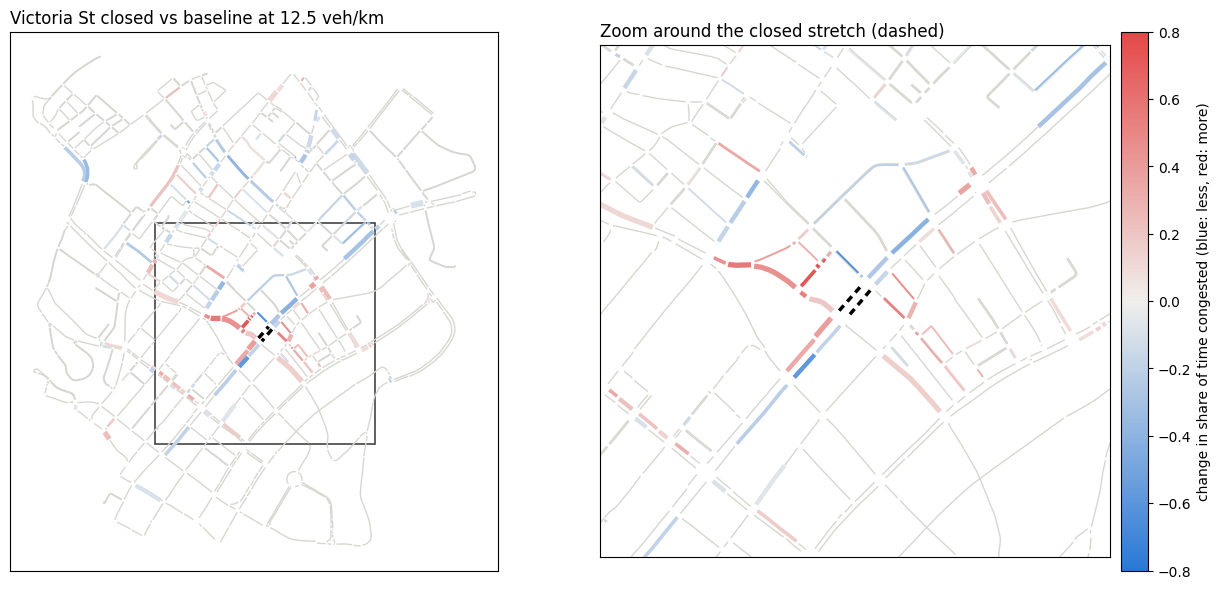

181 roads change consistently at 12.5 veh/km


In [6]:
# --- Visual 4 (static): closure congestion-change map at one density ------------------
edges = pd.read_csv(os.path.join(DATA_DIR, EDGE_FILE))
closure_net = nets["closure"]
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])  # blue - grey - red
norm = TwoSlopeNorm(vcenter=0, vmin=-0.8, vmax=0.8)
CHANGE_MIN = 0.05                                                    # 5 percentage points

def closure_map(k, ax_full, ax_zoom):
    """Draw the closure's change in congested share from the baseline at density k."""
    e = edges[(edges.variant == "closure") & np.isclose(edges.k_target, k)].set_index("edge")
    shown = (e.d_share.abs() >= CHANGE_MIN) & (e.d_same_sign.astype(str) == "True")
    zoom_box = box_around(closed, base, 600)
    for ax in (ax_full, ax_zoom):
        ax.clear()
        grey = [s for eid, (s, n) in closure_net.items() if not shown.get(eid, False)]
        ax.add_collection(LineCollection(grey, colors="#d7d6d0", linewidths=1.0))
        col = sorted([(abs(e.d_share[eid]), s, n, e.d_share[eid]) for eid, (s, n) in closure_net.items()
                      if shown.get(eid, False)], key=lambda t: t[0])           # biggest changes on top
        if col:
            ax.add_collection(LineCollection([c[1] for c in col], linewidths=[0.8 + 0.6 * c[2] for c in col],
                                             colors=div(norm(np.array([c[3] for c in col])))))
        ax.add_collection(LineCollection([base[x][0] for x in closed], colors="black", linewidths=2.5,
                                         linestyles=(0, (2, 1.5))))
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax_full.autoscale_view()
    ax_full.add_patch(Rectangle((zoom_box[0], zoom_box[2]), zoom_box[1] - zoom_box[0], zoom_box[3] - zoom_box[2],
                                fill=False, ec="#444444", lw=1.2))
    ax_zoom.set_xlim(zoom_box[0], zoom_box[1]); ax_zoom.set_ylim(zoom_box[2], zoom_box[3])
    ax_full.set_title(f"Victoria St closed vs baseline at {k:g} veh/km", loc="left", fontsize=12)
    ax_zoom.set_title("Zoom around the closed stretch (dashed)", loc="left", fontsize=12)
    return int(shown.sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7))
n = closure_map(12.5, a1, a2)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=div), ax=[a1, a2], fraction=0.025, pad=0.01,
             label="change in share of time congested (blue: less, red: more)")
plt.show()
print(f"{n} roads change consistently at 12.5 veh/km")

### The same map with a density slider

Slide through the densities to see how the closure's effect grows as the network fills up. (In Colab the slider appears under the cell; it redraws the map each time you move it.)

In [7]:
# --- Visual 4 (interactive): pick the density with a slider ----------------------------
import ipywidgets as widgets
from IPython.display import display

densities = sorted(edges.k_target.unique())

def show(k):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7))
    n = closure_map(k, a1, a2)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=div), ax=[a1, a2], fraction=0.025, pad=0.01,
                 label="change in share of time congested (blue: less, red: more)")
    plt.show()
    print(f"{n} roads change consistently at {k:g} veh/km")

slider = widgets.SelectionSlider(options=densities, value=12.5, description="veh/km",
                                 continuous_update=False, layout=widgets.Layout(width="600px"))
widgets.interact(show, k=slider);

interactive(children=(SelectionSlider(continuous_update=False, description='veh/km', index=4, layout=Layout(wi…

## 5. Does the new link make its neighbours worse? (the local Braess effect)

The same kind of map as visual 4, now for the **Java Road connection** against the baseline. Network-wide, the link changes speed by less than the seed-to-seed spread (+0.6%, 95% interval −0.7 to +1.9% with 10 seeds), so there is no Braess paradox for the network as a whole. Road by road, it is different:

- **Red:** more congested with the new link. **Blue:** less congested. **Grey:** a change under 5 percentage points, or one the seeds don't agree on.
- **Thick dark line:** the new link (148 m, Republic Ave ramp to Beach Rd).

At **25 veh/km** the baseline and the new link have **10 seeds**, so a road is coloured only if all ten seed pairs change in the same direction. The five roads right beside the link all turn red, while only a handful of scattered roads change anywhere else: a **local** Braess-like effect that does not spread. The table under the map lists every coloured road with its distance from the link.

*Note:* 25, 30 and 35 veh/km have 10 seeds; the other densities have 3, so their maps show more scattered roads by chance.

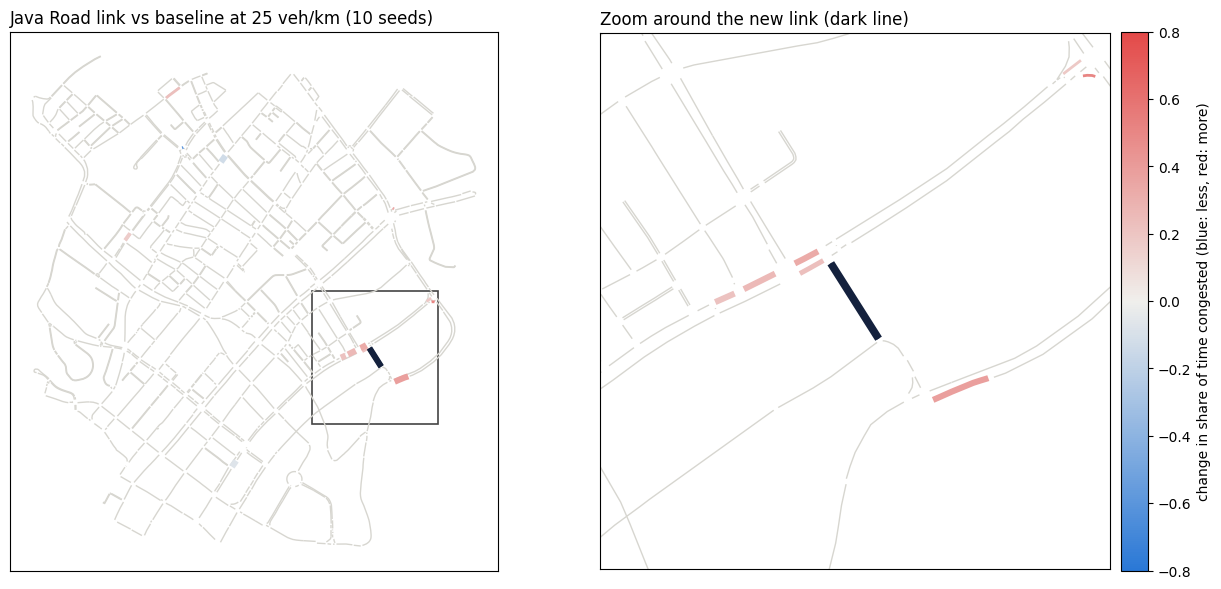

14 of 1129 shared roads change consistently at 25 veh/km (10 seeds).
Within 250 m of the link: 5 roads, 5 of them more congested.


,road,street,change in congested share,congested share with link,distance from link (m)
0,538223034,Beach Road,0.23,0.47,79
1,75141904,Beach Road,0.33,0.38,95
2,673787044,Beach Road,0.26,0.60,139
3,762801886,Beach Road,0.22,0.38,186
4,639288915,Republic Avenue,0.38,0.72,200
5,693442241#0,Beach Road,0.19,0.17,458
6,465442464,(unnamed),0.51,0.75,466
7,781959613,Syed Alwi Road,0.24,0.54,756
8,445283032#0,(unnamed),0.34,0.38,872
9,748645713,Beach Road,-0.07,0.10,1029


In [8]:
# --- Visual 5 (static): the new link's congestion-change map, and the roads it affects ----------
newlink_net = nets["newlink"]
link_xy = np.vstack([newlink_net[e][0] for e in new])
link_mid = link_xy.mean(axis=0)                                       # middle of the new link

def street_names(path):
    """{edge id: street name} for the normal roads of a network file."""
    names = {}
    for _, el in ET.iterparse(path):
        if el.tag == "edge" and el.get("function") != "internal":
            names[el.get("id")] = el.get("name") or "(unnamed)"
        el.clear()
    return names

names = street_names(os.path.join(DATA_DIR, NET_FILES["newlink"]))

def newlink_map(k, ax_full, ax_zoom):
    """Draw the new link's change in congested share from the baseline at density k.
    Returns the coloured roads as a table, nearest to the link first, and the number of seeds."""
    e = edges[(edges.variant == "newlink") & np.isclose(edges.k_target, k)].set_index("edge")
    shown = (e.d_share.abs() >= CHANGE_MIN) & (e.d_same_sign.astype(str) == "True")
    zoom_box = box_around(new, newlink_net, 330)
    for ax in (ax_full, ax_zoom):
        ax.clear()
        grey = [s for eid, (s, n) in newlink_net.items() if not shown.get(eid, False) and eid not in new]
        ax.add_collection(LineCollection(grey, colors="#d7d6d0", linewidths=1.0))
        col = sorted([(abs(e.d_share[eid]), s, n, e.d_share[eid]) for eid, (s, n) in newlink_net.items()
                      if shown.get(eid, False)], key=lambda t: t[0])           # biggest changes on top
        if col:
            ax.add_collection(LineCollection([c[1] for c in col], linewidths=[1.2 + 0.8 * c[2] for c in col],
                                             colors=div(norm(np.array([c[3] for c in col])))))
        ax.add_collection(LineCollection([newlink_net[x][0] for x in new], colors="#14213D", linewidths=4))
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax_full.autoscale_view()
    ax_full.add_patch(Rectangle((zoom_box[0], zoom_box[2]), zoom_box[1] - zoom_box[0], zoom_box[3] - zoom_box[2],
                                fill=False, ec="#444444", lw=1.2))
    ax_zoom.set_xlim(zoom_box[0], zoom_box[1]); ax_zoom.set_ylim(zoom_box[2], zoom_box[3])
    n_seeds = int(e.n_seeds.max())
    ax_full.set_title(f"Java Road link vs baseline at {k:g} veh/km ({n_seeds} seeds)", loc="left", fontsize=12)
    ax_zoom.set_title("Zoom around the new link (dark line)", loc="left", fontsize=12)
    rows = [{"road": eid, "street": names.get(eid, ""),
             "change in congested share": round(e.d_share[eid], 2),
             "congested share with link": round(e.congested_share[eid], 2),
             "distance from link (m)": round(float(np.linalg.norm(newlink_net[eid][0].mean(axis=0) - link_mid)))}
            for eid in e.index[shown] if eid in newlink_net]
    table = pd.DataFrame(rows).sort_values("distance from link (m)").reset_index(drop=True) if rows else pd.DataFrame()
    return table, n_seeds

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7))
affected, n_seeds = newlink_map(25, a1, a2)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=div), ax=[a1, a2], fraction=0.025, pad=0.01,
             label="change in share of time congested (blue: less, red: more)")
plt.show()

near = affected[affected["distance from link (m)"] <= 250]
print(f"{len(affected)} of {len(newlink_net) - len(new)} shared roads change consistently at 25 veh/km ({n_seeds} seeds).")
print(f"Within 250 m of the link: {len(near)} roads, {int((near['change in congested share'] > 0).sum())} of them more congested.")
display(affected)

### The same map with a density slider

Move the slider to see the new link's effect at other densities. Watch the seed count in the title: with 3 seeds, many more scattered roads pass the test by chance.

In [9]:
# --- Visual 5 (interactive): pick the density with a slider ----------------------------
def show_newlink(k):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 7))
    affected, n_seeds = newlink_map(k, a1, a2)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=div), ax=[a1, a2], fraction=0.025, pad=0.01,
                 label="change in share of time congested (blue: less, red: more)")
    plt.show()
    print(f"{len(affected)} roads change consistently at {k:g} veh/km ({n_seeds} seeds)")

slider_newlink = widgets.SelectionSlider(options=densities, value=25.0, description="veh/km",
                                         continuous_update=False, layout=widgets.Layout(width="600px"))
widgets.interact(show_newlink, k=slider_newlink);

interactive(children=(SelectionSlider(continuous_update=False, description='veh/km', index=7, layout=Layout(wi…

# Upload these two files in the next cell block (source: branch c/planning-results/results/city/):
###     bugis_all_base_controller_seeds4to10.csv
###     bugis_all_newlink_controller_seeds4to10.csv

In [10]:
from google.colab import files

uploaded = files.upload()

# Optional: Print the name and size of each uploaded file
for filename in uploaded.keys():
    print(f'Uploaded "{filename}" ({len(uploaded[filename])} bytes)')

Saving bugis_all_newlink_controller_seeds4to10.csv to bugis_all_newlink_controller_seeds4to10.csv
Saving bugis_all_base_controller_seeds4to10.csv to bugis_all_base_controller_seeds4to10.csv
Uploaded "bugis_all_newlink_controller_seeds4to10.csv" (15692 bytes)
Uploaded "bugis_all_base_controller_seeds4to10.csv" (15653 bytes)


In [11]:
# --- Extra files for the Braess test: seeds 4-10 of the baseline and the new link ------------
# The Braess plot below compares the network with and without the Java Road link at 25, 30 and
# 35 veh/km. Seeds 1-3 of both networks are already loaded: they are in the two controller
# tables the setup cell found (RESULT_FILES["base"] and RESULT_FILES["newlink"]).
# Because 3 seeds were too few to tell a real effect from noise, C ran 7 more seeds (4-10) for
# these two networks at those three densities. They are kept in two separate tables on C's
# branch c/planning-results, next to the other controller CSVs:
#     bugis_all_base_controller_seeds4to10.csv
#     bugis_all_newlink_controller_seeds4to10.csv
# This cell finds them (Option B: anywhere in your local repository) or asks you to upload
# them (Option A: Colab), exactly like the setup cell does for the other 9 files.
EXTRA_FILES = {v: f"bugis_all_{v}_controller_seeds4to10.csv" for v in ("base", "newlink")}

if globals().get("REPO_DIR"):                  # Option B: search the repository for each file
    EXTRA_FILES = {v: find(f, CSV_FOLDERS) for v, f in EXTRA_FILES.items()}
    for f in EXTRA_FILES.values():
        print("using", f)

missing = [f for f in EXTRA_FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    try:                                       # Option A (Colab): open the upload dialog
        from google.colab import files
        print("Please upload:", ", ".join(missing))
        files.upload()
    except ImportError:                        # not in Colab: just say what is missing
        print("Missing files (put them in DATA_DIR):", ", ".join(missing))
missing = [f for f in EXTRA_FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
print("Both seeds 4-10 files found." if not missing else f"Still missing: {missing}")

Both seeds 4-10 files found.


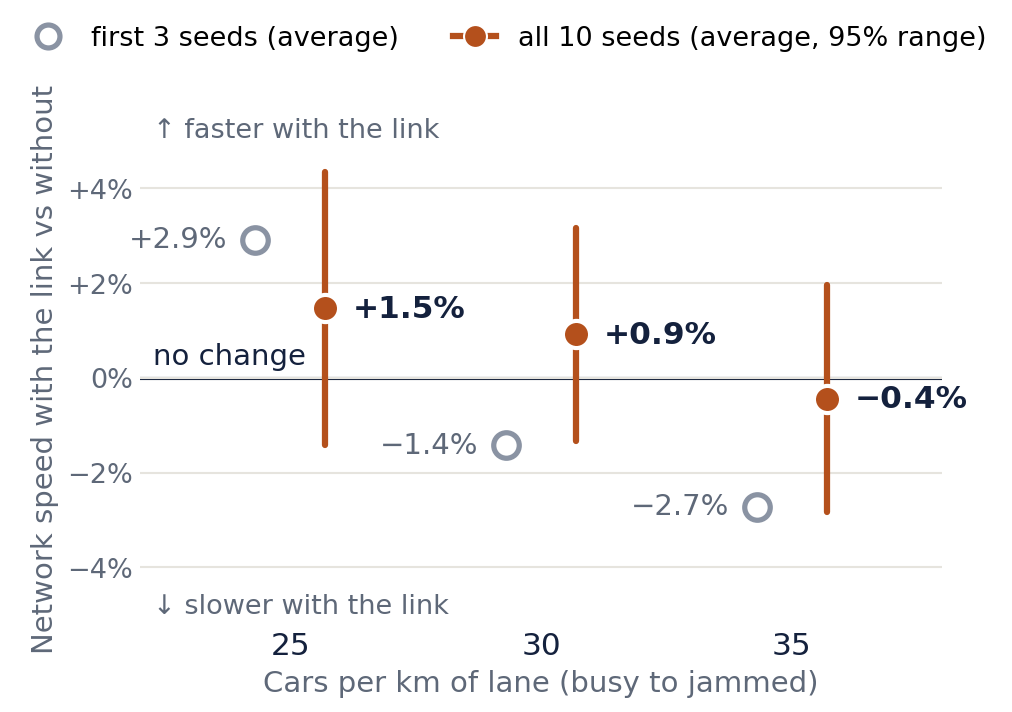

,density (veh/km),first 3 seeds (%),all seeds (%),95% low (%),95% high (%),seed pairs
0,25,2.91,1.46,-1.41,4.33,9
1,30,-1.42,0.91,-1.33,3.16,8
2,35,-2.72,-0.44,-2.82,1.94,10


Pooled over 25-35 veh/km: +0.59% (95% interval -0.70 to +1.89%), 27 seed pairs


In [12]:
# --- Visual 6: the Braess test, network speed with the Java Road link vs without -----------
# Uses RESULT_FILES (seeds 1-3, from the setup cell) and EXTRA_FILES (seeds 4-10, cell above).
from scipy import stats
from matplotlib.lines import Line2D

def load_10_seeds(v):
    """Valid runs of one network, seeds 1-10: seed, density and network mean speed."""
    d = pd.concat([pd.read_csv(os.path.join(DATA_DIR, RESULT_FILES[v])),    # seeds 1-3
                   pd.read_csv(os.path.join(DATA_DIR, EXTRA_FILES[v]))])    # seeds 4-10
    return d[d["valid"].astype(str) == "True"][["seed", "city_k_target", "mean_speed_mps"]]

# Pair each new-link run with the baseline run of the same seed and density (a failed run drops its pair)
m = load_10_seeds("newlink").merge(load_10_seeds("base"), on=["seed", "city_k_target"], suffixes=("", "_b"))
m["pct"] = 100 * (m.mean_speed_mps / m.mean_speed_mps_b - 1)   # % change in network speed

K = [25, 30, 35]                                               # the densities with 10 seeds
INK, MUTED, GRID, ORANGE, GREY = "#14213D", "#5E6878", "#E6E4DE", "#B4501C", "#8A93A3"
minus = lambda s: s.replace("-", "\u2212")                     # typographic minus sign

fig, ax = plt.subplots(figsize=(6.6, 4.95), dpi=150)
fig.subplots_adjust(left=0.16, right=0.97, top=0.84, bottom=0.15)
ax.axhline(0, color=INK, lw=1.5, zorder=1)
ax.text(-0.55, 0.15, "no change", ha="left", va="bottom", fontsize=14, color=INK)
rows = []
for i, k in enumerate(K):
    g = m[m.city_k_target == k]
    three = g[g.seed <= 3].pct.mean()                          # what the first 3 seeds showed
    x = g.pct; n = len(x); mu = x.mean()
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)  # half-width of the 95% t-interval
    rows.append({"density (veh/km)": k, "first 3 seeds (%)": round(three, 2), "all seeds (%)": round(mu, 2),
                 "95% low (%)": round(mu - h, 2), "95% high (%)": round(mu + h, 2), "seed pairs": n})
    ax.scatter(i - 0.14, three, s=150, facecolor="white", edgecolor=GREY, lw=2.5, zorder=3)
    ax.text(i - 0.25, three, minus(f"{three:+.1f}%"), ha="right", va="center", fontsize=14, color=MUTED)
    ax.plot([i + 0.14] * 2, [mu - h, mu + h], color=ORANGE, lw=3, solid_capstyle="round", zorder=2)
    ax.scatter(i + 0.14, mu, s=170, color=ORANGE, edgecolor="white", lw=2, zorder=4)
    ax.text(i + 0.25, mu, minus(f"{mu:+.1f}%"), ha="left", va="center", fontsize=15, color=INK, fontweight="bold")
ax.set_xticks(range(len(K))); ax.set_xticklabels([str(k) for k in K], fontsize=15, color=INK)
ax.set_xlim(-0.6, 2.6); ax.set_ylim(-5.2, 5.6)
ax.set_yticks(range(-4, 5, 2))
ax.set_yticklabels([minus(f"{t:+d}%") if t else "0%" for t in range(-4, 5, 2)], fontsize=13, color=MUTED)
ax.set_xlabel("Cars per km of lane (busy to jammed)", fontsize=14, color=MUTED)
ax.set_ylabel("Network speed with the link vs without", fontsize=14, color=MUTED)
ax.text(-0.55, 5.5, "\u2191 faster with the link", fontsize=13, color=MUTED, va="top")
ax.text(-0.55, -5.1, "\u2193 slower with the link", fontsize=13, color=MUTED, va="bottom")
ax.grid(axis="y", color=GRID, lw=1, zorder=0)
for s in ("top", "right", "left", "bottom"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=11, mfc="white", mec=GREY, mew=2.5, label="first 3 seeds (average)"),
                    Line2D([], [], marker="o", ls="-", lw=3, ms=11, color=ORANGE, mec="white",
                           label="all 10 seeds (average, 95% range)")],
           loc="upper left", bbox_to_anchor=(0.02, 0.99), ncol=2, fontsize=13, frameon=False, handlelength=1.6)
fig.savefig("braess_simple.png", dpi=300, facecolor="white")
plt.show()

pooled = m[m.city_k_target.isin(K)].pct
h = stats.t.ppf(0.975, len(pooled) - 1) * pooled.std(ddof=1) / np.sqrt(len(pooled))
display(pd.DataFrame(rows))
print(f"Pooled over {K[0]}-{K[-1]} veh/km: {pooled.mean():+.2f}% "
      f"(95% interval {pooled.mean() - h:+.2f} to {pooled.mean() + h:+.2f}%), {len(pooled)} seed pairs")